In [ ]:
# Locate the repository root (works regardless of the launch directory) and expose it on sys.path.
import os, sys
_p = os.path.abspath(os.getcwd())
while _p != os.path.dirname(_p) and not os.path.exists(os.path.join(_p, 'src', 'config.py')):
    _p = os.path.dirname(_p)
BASE = _p
sys.path.insert(0, BASE)
sys.path.insert(0, os.path.join(BASE, 'ana'))
from src.config import BIOMEDBERT


# Text + Pathway Cross-Attention


In [ ]:

import os, sys, datetime
os.environ['PROMPTCASL_SPLIT'] = 'gplo'
sys.path.insert(0, os.path.join(BASE, 'ana'))
import model_version as MV
print(MV.summary())


In [26]:
import sys, os
sys.path.insert(0, os.path.join(BASE, 'ana'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import text_pathway_attn as T          # validated helpers (prompt reconstruction + attention decode)
plt.rcParams.update({'figure.dpi': 130, 'font.size': 11}); sns.set_style('whitegrid')

R = T.load_cache('pair_K16')
ok, ch = T.verify_alignment(R)
print(f'PPE K16 records: {len(R)}   prompt-reconstruction alignment: {ok}/{ch} masks elementwise-equal')

PPE K16 records: 6662   prompt-reconstruction alignment: 5/5 masks elementwise-equal


## Gene-pair queries retrieve both text and pathway-level context tokens


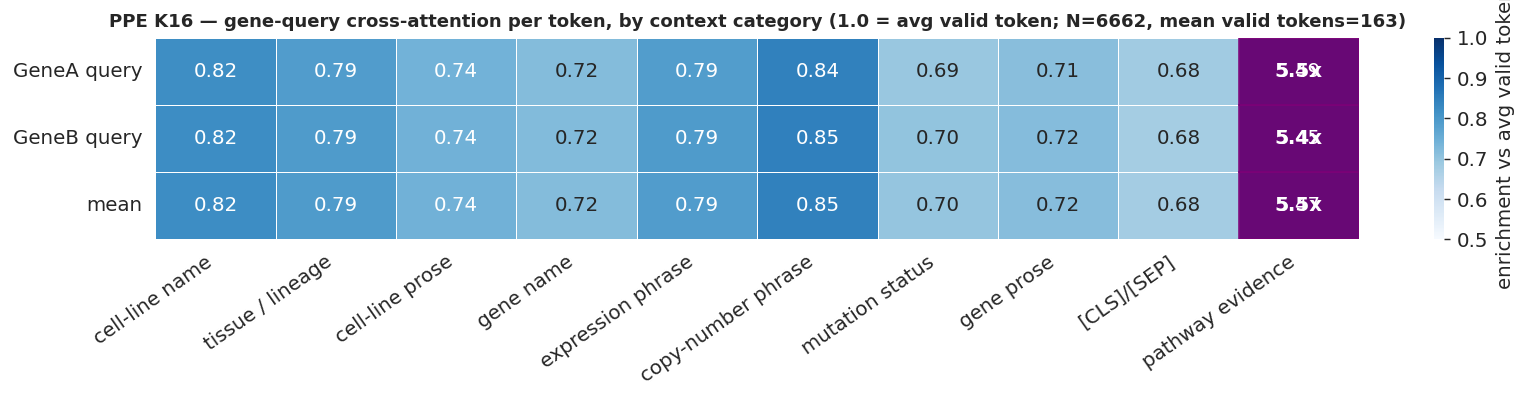

      CLNAME  LINEAGE  CELLBG  GENENAME  EXPR  CNV  MUT  GENEBG  SPECIAL  PATHWAY
A       0.82     0.79    0.74      0.72  0.79 0.84 0.69    0.71     0.68     5.49
B       0.82     0.79    0.74      0.72  0.79 0.85 0.70    0.72     0.68     5.45
mean    0.82     0.79    0.74      0.72  0.79 0.85 0.70    0.72     0.68     5.47

mean #tokens/record per category: {'CLNAME': 7.1, 'LINEAGE': 7.2, 'CELLBG': 53.3, 'GENENAME': 4.7, 'EXPR': 24.6, 'CNV': 26.5, 'MUT': 5.9, 'GENEBG': 24.0, 'SPECIAL': 2.0, 'PATHWAY': 8.1}


In [ ]:
df, counts, N, mean_valid = T.category_enrichment(R)
cols = T.CATS + ['PATHWAY']
xticklabels = [T.CAT_LABEL[c] for c in cols]
rows_lbl = ['GeneA query', 'GeneB query', 'mean']

fig, ax = plt.subplots(figsize=(13, 3.2))

sns.heatmap(df[cols].values, annot=True, fmt='.2f', cmap='Blues',
            vmin=0.5, vmax=1, cbar_kws={'label': 'enrichment vs avg valid token'},
            xticklabels=xticklabels, yticklabels=rows_lbl, linewidths=.5, linecolor='white', ax=ax)
for yi in range(3):
    ax.add_patch(plt.Rectangle((len(cols)-1, yi), 1, 1, fill=True, color='#7a0177', alpha=.85, zorder=2))
    ax.text(len(cols)-0.5, yi+0.5, f'{df[cols].values[yi,-1]:.1f}x', ha='center', va='center',
            color='white', fontweight='bold', zorder=3)
ax.set_xticklabels(xticklabels, rotation=35, ha='right')
ax.set_title(f'PPE K16 — gene-query cross-attention per token, by context category '
             f'(1.0 = avg valid token; N={N}, mean valid tokens={mean_valid:.0f})', fontweight='bold', fontsize=10)
plt.tight_layout(); plt.show()

pd.set_option('display.float_format', lambda x: f'{x:.2f}')
print(df[cols].round(2).to_string())
print('\nmean #tokens/record per category:', {k: round(v,1) for k,v in counts.items()})

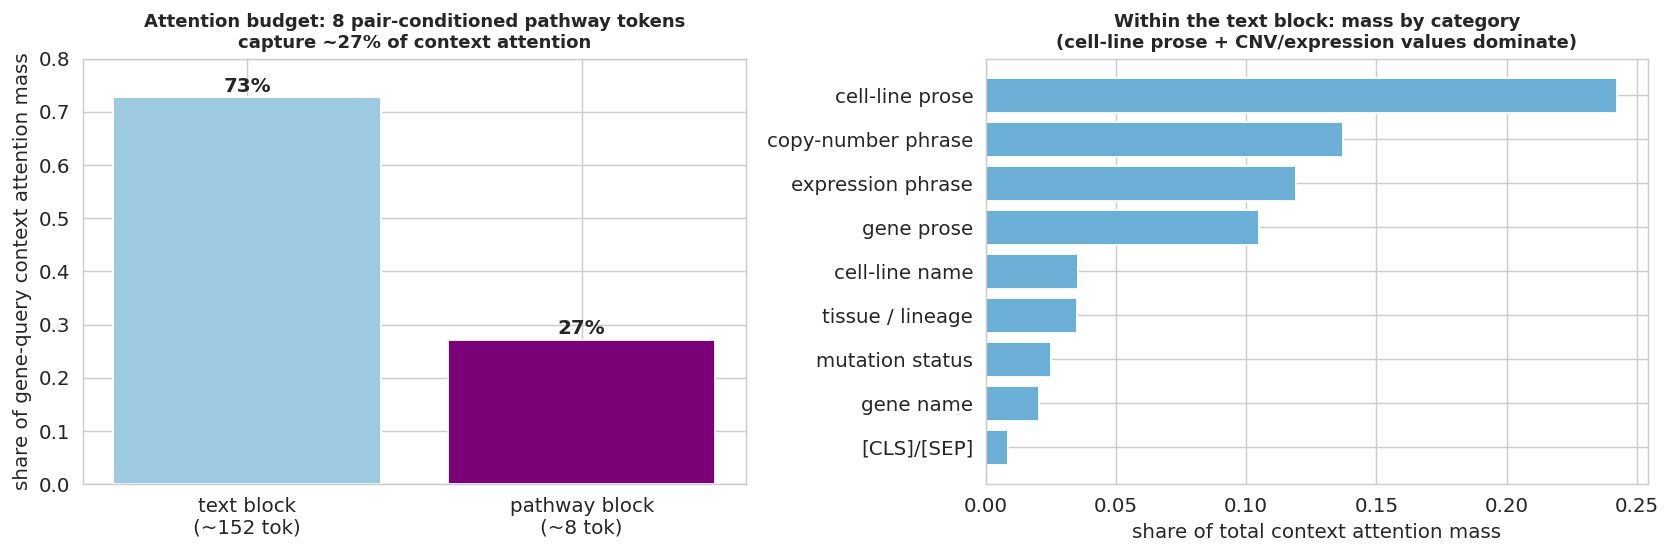

mass share: {'CLNAME': 0.036, 'LINEAGE': 0.035, 'CELLBG': 0.242, 'GENENAME': 0.021, 'EXPR': 0.119, 'CNV': 0.137, 'MUT': 0.025, 'GENEBG': 0.105, 'SPECIAL': 0.008, 'PATHWAY': 0.272}


In [29]:
# Total attention mass (fractions sum to 1), text block vs pathway block,
# and the within-text breakdown.

share, _ = T.mass_split(R)
text_share = sum(share[c] for c in T.CATS)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
axes[0].bar(['text block\n(~152 tok)', 'pathway block\n(~8 tok)'], [text_share, share['PATHWAY']],
            color=['#9ecae1', '#7a0177'])
for i, v in enumerate([text_share, share['PATHWAY']]):
    axes[0].text(i, v+0.01, f'{v:.0%}', ha='center', fontweight='bold')
axes[0].set_ylabel('share of gene-query context attention mass'); axes[0].set_ylim(0, 0.8)
axes[0].set_title('Attention budget: text block vs pathway block',
                  fontweight='bold', fontsize=10)
order = ['CELLBG','CNV','EXPR','GENEBG','CLNAME','LINEAGE','MUT','GENENAME','SPECIAL']
axes[1].barh([T.CAT_LABEL[c] for c in order][::-1], [share[c] for c in order][::-1], color='#6baed6')
axes[1].set_xlabel('share of total context attention mass')
axes[1].set_title('Within the text block: attention mass by category',
                  fontweight='bold', fontsize=10)
plt.tight_layout(); plt.show()
print('mass share:', {k: round(v,3) for k,v in share.items()})

## Fine-tuning the LLM redistributes gene-query context attention


paired records (full vs frozen-LLM): 6662   (*_mean = share of gene-query context-attention budget / mass)

                       label  full_mean  frozen_mean  delta  pct_full_gt  rank_biserial  wilcoxon_p
category                                                                                           
CLNAME        cell-line name       0.04         0.04  -0.01         0.36          -0.29        0.00
LINEAGE     tissue / lineage       0.04         0.04  -0.01         0.36          -0.29        0.00
CELLBG       cell-line prose       0.24         0.27  -0.02         0.40          -0.19        0.00
GENENAME           gene name       0.02         0.03  -0.01         0.28          -0.43        0.00
EXPR       expression phrase       0.12         0.12  -0.01         0.45          -0.10        0.00
CNV       copy-number phrase       0.14         0.14   0.00         0.47          -0.05        0.01
MUT          mutation status       0.03         0.03  -0.00         0.43          -0.14     

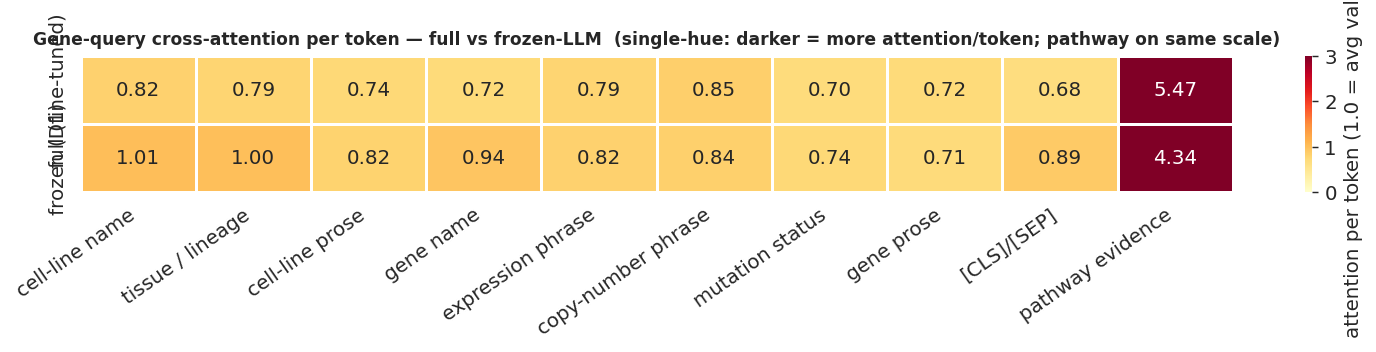


fine full-vs-frozen contrast is quantified in the table above (delta / rank_biserial); the heatmap shows the per-token concentration landscape.


In [ ]:

R_frozen = T.load_cache('pair_K16_D1frozen')
cmp, n_pair = T.compare_caches(R, R_frozen)
print(f'paired records (full vs frozen-LLM): {n_pair}   '
      f'(*_mean = share of gene-query context-attention budget / mass)\n')
print(cmp[['label', 'full_mean', 'frozen_mean', 'delta', 'pct_full_gt', 'rank_biserial', 'wilcoxon_p']]
      .round(4).to_string())


dff, _, _, _ = T.category_enrichment(R)
dfz, _, _, _ = T.category_enrichment(R_frozen)
cols = T.CATS + ['PATHWAY']; xl = [T.CAT_LABEL[c] for c in cols]
mat = pd.concat([dff.loc[['mean'], cols], dfz.loc[['mean'], cols]])
mat.index = ['full (fine-tuned)', 'frozen (D1)']
fig, ax = plt.subplots(figsize=(12, 2.7))
sns.heatmap(mat.values, annot=True, fmt='.2f', cmap='YlOrRd', vmin=0, vmax=3.0, # vmax=float(mat.values.max()),
            xticklabels=xl, yticklabels=mat.index, linewidths=.6, linecolor='white',
            cbar_kws={'label': 'attention per token (1.0 = avg valid token)'}, ax=ax)
ax.set_xticklabels(xl, rotation=35, ha='right')
ax.set_title('Gene-query cross-attention per token — full vs frozen-LLM  '
             '(single-hue: darker = more attention/token; pathway on same scale)',
             fontweight='bold', fontsize=9.5)
plt.tight_layout(); plt.show()
print('\nfine full-vs-frozen contrast is quantified in the table above (delta / rank_biserial); '
      'the heatmap shows the per-token concentration landscape.')

## Fine-tuning and BiomedBERT self-attention

Per-token attention received by category, stock vs fine-tuned encoder, by layer.


records: 6662   layers: 12   (paired comparison at last layer)

                       label  stock  finetuned  delta  pct_ft_gt  rank_biserial  wilcoxon_p
category                                                                                   
CLNAME        cell-line name   0.22       0.83   0.61       0.68           0.35        0.00
LINEAGE     tissue / lineage   0.38       0.55   0.16       0.67           0.33        0.00
CELLBG       cell-line prose   1.39       0.94  -0.45       0.06          -0.88        0.00
GENENAME           gene name   0.26       0.59   0.33       0.74           0.47        0.00
EXPR       expression phrase   0.16       0.45   0.29       0.97           0.95        0.00
CNV       copy-number phrase   0.20       0.59   0.39       0.98           0.95        0.00
MUT          mutation status   0.23       0.20  -0.03       0.34          -0.32        0.00
GENEBG            gene prose   1.50       1.55   0.04       0.37          -0.26        0.00
SPECIAL         

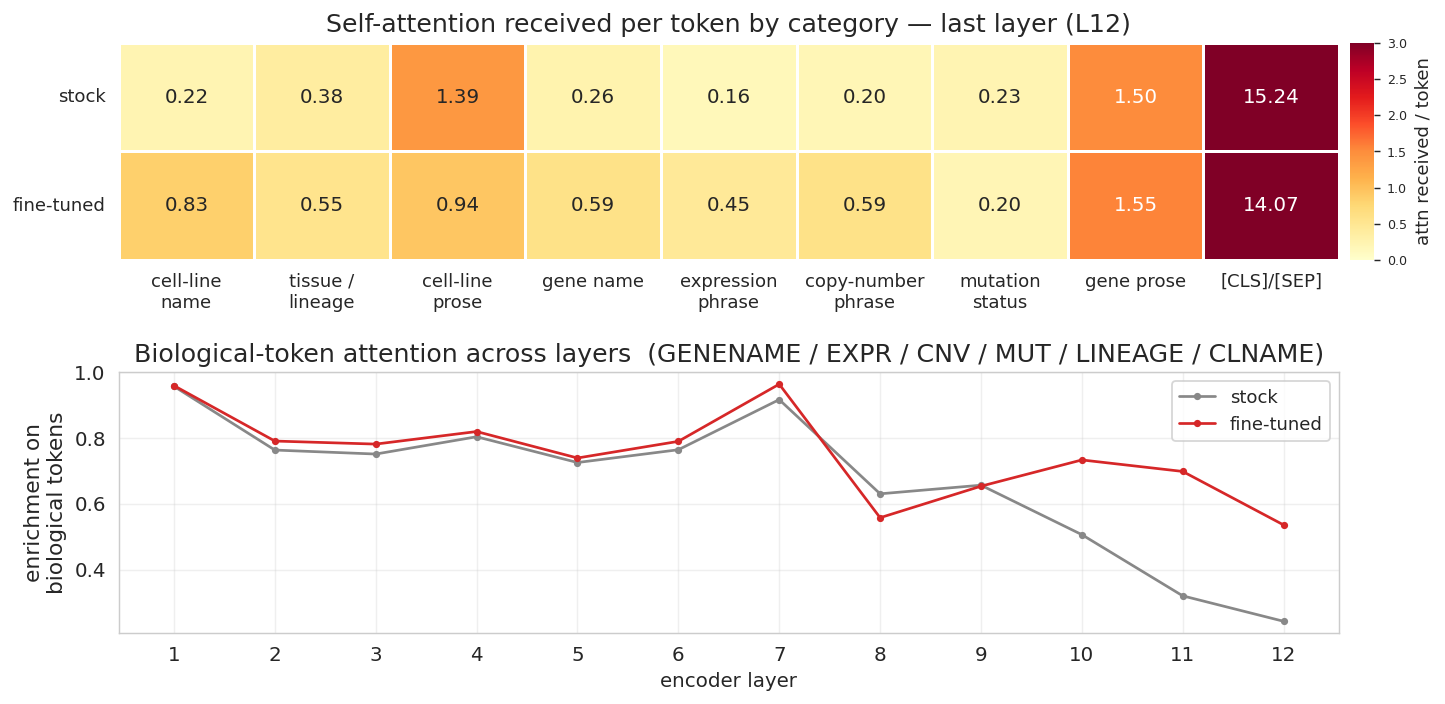


biological-token enrichment (last layer): stock=0.243  fine-tuned=0.536  delta=+0.293
per-layer (fine-tuned - stock) on biological tokens: L1:+0.002, L2:+0.027, L3:+0.030, L4:+0.016, L5:+0.014, L6:+0.026, L7:+0.047, L8:-0.073, L9:-0.003, L10:+0.227, L11:+0.378, L12:+0.293


In [ ]:

d = T.load_selfattn_cache()
n_layers = d['enr_stock'].shape[1]
cmpS = T.selfattn_compare(d, layer=-1)
print(f'records: {d["enr_stock"].shape[0]}   layers: {n_layers}   (paired comparison at last layer)\n')
print(cmpS[['label', 'stock', 'finetuned', 'delta', 'pct_ft_gt', 'rank_biserial', 'wilcoxon_p']]
      .round(4).to_string())

cats = list(d['cats']); xl = [T.CAT_LABEL.get(c, c) for c in cats]

import textwrap
fig = plt.figure(figsize=(11, 5.3), layout='constrained')
gs = fig.add_gridspec(2, 2, width_ratios=[1, .02], height_ratios=[1, 1.2], wspace=.015, hspace=.09)
axH, caxH, axP = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, 0])

CLAMP = 3.0
M = np.vstack([cmpS['stock'].values, cmpS['finetuned'].values])
sns.heatmap(M, annot=True, fmt='.2f', cmap='YlOrRd', vmin=0, vmax=CLAMP,
            xticklabels=xl, yticklabels=['stock', 'fine-tuned'], linewidths=.6, linecolor='white',
            cbar_ax=caxH, cbar_kws={'label': 'attn received / token'}, ax=axH)
caxH.yaxis.label.set_size(10); caxH.tick_params(labelsize=7)
axH.set_xticklabels(['\n'.join(textwrap.wrap(t, 12)) for t in xl], rotation=0, fontsize=10)
axH.set_yticklabels(['stock', 'fine-tuned'], rotation=0, fontsize=10)
axH.set_title(f'Self-attention received per token by category — last layer (L{n_layers})', fontsize=14)
# (bottom) per-layer profile: biological-category enrichment across layers, stock vs fine-tuned
ps, pf = T.selfattn_layer_profile(d)
L = np.arange(1, n_layers + 1)
axP.plot(L, ps, '-o', ms=3, color='#888888', label='stock')
axP.plot(L, pf, '-o', ms=3, color='#d62728', label='fine-tuned')
axP.set_xticks(L)
axP.set_xlabel('encoder layer'); axP.set_ylabel('enrichment on\nbiological tokens', fontsize=12)
axP.set_title('Biological-token attention across layers  (' + ' / '.join(T.BIO_CATS) + ')', fontsize=14)
axP.legend(fontsize=10); axP.grid(alpha=.3)
plt.show()   # no tight_layout(): constrained layout above already owns the spacing

dbio = pf - ps
print(f'\nbiological-token enrichment (last layer): stock={ps[-1]:.3f}  fine-tuned={pf[-1]:.3f}  '
      f'delta={pf[-1]-ps[-1]:+.3f}')
print('per-layer (fine-tuned - stock) on biological tokens:',
      ', '.join(f'L{i+1}:{v:+.3f}' for i, v in enumerate(dbio)))